In [5]:
import csv
import numpy as np
import matplotlib.pyplot as plt

# Read the sweep results
with open("sweep_results.csv", newline="") as file:
    results = list(csv.DictReader(file))

# Convert the numeric columns from text to numbers
for case in results:
    case["v_start"] = float(case["v_start"])
    case["gamma_start_deg"] = float(case["gamma_start_deg"])
    case["max_load_g"] = float(case["max_load_g"])

# Read the refined boundaries
with open("boundary_results.csv", newline="") as file:
    boundaries = list(csv.DictReader(file))

for boundary in boundaries:
    boundary["v_start"] = float(boundary["v_start"])
    boundary["angle_a_deg"] = float(boundary["angle_a_deg"])
    boundary["angle_b_deg"] = float(boundary["angle_b_deg"])

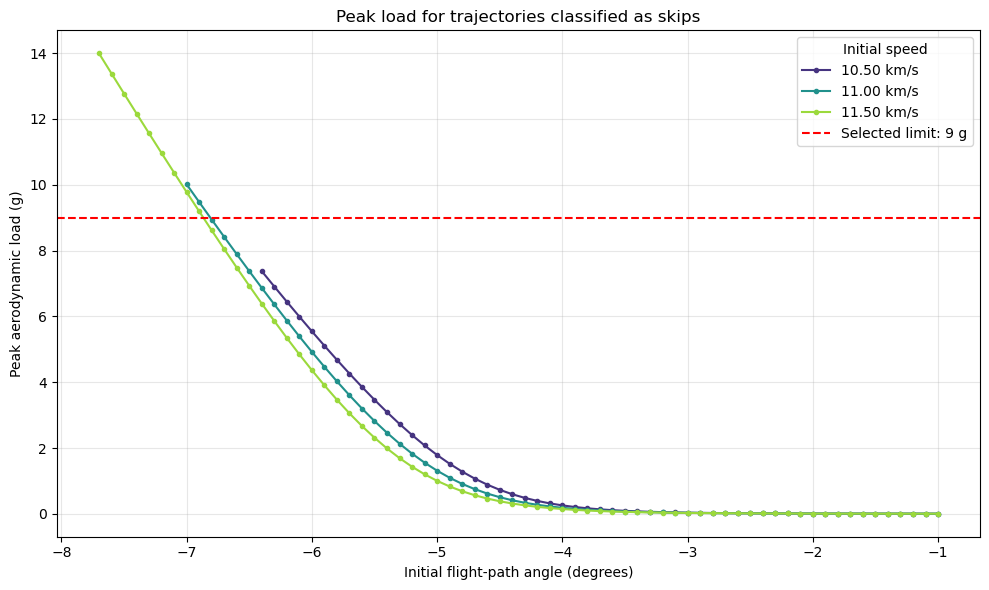

Refined boundaries:
10.50 km/s | skip boundary: -6.4086° to -6.4078°
11.00 km/s | skip boundary: -7.0992° to -7.0984°
11.00 km/s | load boundary: -6.8117° to -6.8109°
11.50 km/s | skip boundary: -7.7539° to -7.7531°
11.50 km/s | load boundary: -6.8672° to -6.8664°

Saved peak_load_vs_entry_angle.png


In [6]:
# Find the speeds included in the saved results
speeds = sorted(set(case["v_start"] for case in results))
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(speeds)))

fig, ax = plt.subplots(figsize=(10, 6))

for speed, color in zip(speeds, colors):
    cases = sorted(
        [case for case in results if case["v_start"] == speed],
        key=lambda case: case["gamma_start_deg"]
    )

    angles = [case["gamma_start_deg"] for case in cases]

    # NaN leaves non-skip trajectories off the plot.
    loads = [
        case["max_load_g"] if case["outcome"] == "skip" else np.nan
        for case in cases
    ]

    ax.plot(
        angles,
        loads,
        marker="o",
        markersize=3,
        color=color,
        label=f"{speed / 1000:.2f} km/s"
    )

ax.axhline(
    9.0,
    color="red",
    linestyle="--",
    label="Selected limit: 9 g"
)

ax.set_xlabel("Initial flight-path angle (degrees)")
ax.set_ylabel("Peak aerodynamic load (g)")
ax.set_title("Peak load for trajectories classified as skips")
ax.grid(True, alpha=0.3)
ax.legend(title="Initial speed")

plt.tight_layout()

# Save an image for the report
plt.savefig("peak_load_vs_entry_angle.png", dpi=300, bbox_inches="tight")

plt.show()


# Print the refined boundaries
print("Refined boundaries:")

if not boundaries:
    print("No boundaries found in the sampled range.")
else:
    for boundary in boundaries:
        print(
            f"{boundary['v_start'] / 1000:.2f} km/s | "
            f"{boundary['boundary_type']} boundary: "
            f"{boundary['angle_a_deg']:.4f}° to "
            f"{boundary['angle_b_deg']:.4f}°"
        )

print("\nSaved peak_load_vs_entry_angle.png")